# NAVTTC Artificial Intelligence & Machine Learning
## Student Name: Muhammad Abdullah
### Week 5 - Task 52: Machine Learning - Logistic Regression with Scikit-Learn
- **Domain / Module:** Machine Learning I
- **Task Description:** Implement Logistic Regression for classification, compute confusion matrix, and evaluate precision, recall, and ROC-AUC.
- **Reference / Resource:** https://towardsdatascience.com/logistic-regression-using-python-sklearn-numpy-mnist-handwriting-recognition-matplotlib-a6b31e2b166a

---

### 1. Conceptual Background
Logistic Regression is a foundational classification algorithm used when the target variable is categorical. It maps linear combinations of features through the **logistic sigmoid function**:
$$\sigma(z) = \frac{1}{1 + e^{-z}}$$
producing outputs bounded between 0 and 1, representing class posterior probabilities $P(y=1|X)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Load standard binary classification benchmark dataset
data = load_breast_cancer()
X, y = data.data, data.target
target_names = data.target_names

# Train-test split (75/25)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Feature standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression model
clf = LogisticRegression(random_state=42, max_iter=1000)
clf.fit(X_train_scaled, y_train)

# Predictions
y_pred = clf.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
print(f'Test Accuracy: {acc * 100:.2f}%\n')
print('Classification Report:\n', classification_report(y_test, y_pred, target_names=target_names))

Test Accuracy: 98.60%

Classification Report:
               precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



### 2. Confusion Matrix Heatmap Visualization
Visualizing True Positives, True Negatives, False Positives, and False Negatives.

<string>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


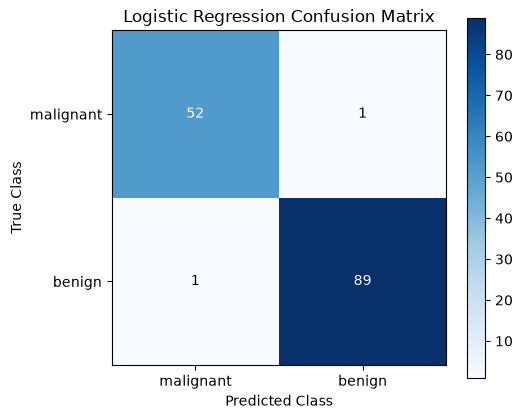

In [2]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title('Logistic Regression Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(len(target_names))
plt.xticks(tick_marks, target_names)
plt.yticks(tick_marks, target_names)

thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 ha='center', va='center',
                 color='white' if cm[i, j] > thresh else 'black')

plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.show()